<h1><center>Векторные представления слов и текстов</center></h1>


Компьютер не понимает слова, он понимает символы, которые представляются числами. Компьютер есть только числа...


<h2>Мешок слов</h2>

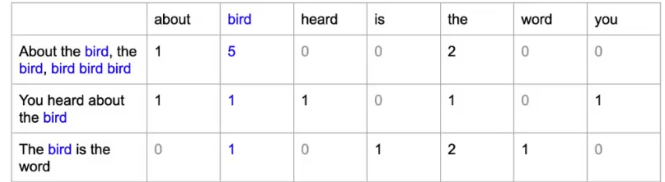

Достаточно поплуряна в глубоком обучении. Проста как пять пальцев, подсчитываем число слов.

In [1]:
import re


text1 = 'Мой дядя самых честных правил'
text2 = 'Чего не скажешь о моих не самых честных племянниках'
text3 = 'Изначально я и подумать не мог, что это займёт так много времени'
text4 = 'Ой, да ладно'


def bag_of_words(texts):
    texts = [re.sub(r'^\w\s', '', text.lower()) for text in texts]
    dictionary = {}
    idx = 0
    for text in texts:
        for word in text.split():
            if word not in dictionary:
                dictionary[word] = idx
                idx += 1
    corpora_bag = []
    for text in texts:
        dict_counter = {key: value for key, value in zip(dictionary.keys(),
        [0 for _ in range(len(dictionary))])}
        text_bag = [0 for pos in range(len(dictionary))]
        for word in text.split():
            dict_counter[word] += 1
            text_bag[dictionary[word]] = dict_counter[word]
        corpora_bag.append(text_bag)
    return corpora_bag, dictionary.keys()



bag_of_word, feature_names = bag_of_words([text1, text2, text3, text4])
feature_names

dict_keys(['мой', 'дядя', 'самых', 'честных', 'правил', 'чего', 'не', 'скажешь', 'о', 'моих', 'племянниках', 'изначально', 'я', 'и', 'подумать', 'мог,', 'что', 'это', 'займёт', 'так', 'много', 'времени', 'ой,', 'да', 'ладно'])

In [2]:
bag_of_word

[[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 1, 1, 0, 1, 2, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1]]

In [3]:
len(feature_names)

25

In [4]:
from sklearn.feature_extraction.text import CountVectorizer


vectorizer = CountVectorizer()
X = vectorizer.fit_transform([text1, text2, text3, text4])
vectorizer.get_feature_names_out()


array(['времени', 'да', 'дядя', 'займёт', 'изначально', 'ладно', 'много',
       'мог', 'моих', 'мой', 'не', 'ой', 'племянниках', 'подумать',
       'правил', 'самых', 'скажешь', 'так', 'чего', 'честных', 'что',
       'это'], dtype=object)

In [5]:
len(vectorizer.get_feature_names_out())

22

In [6]:
X.toarray()

array([[0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 2, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0],
       [1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1],
       [0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

<h2>GloVe</h2>

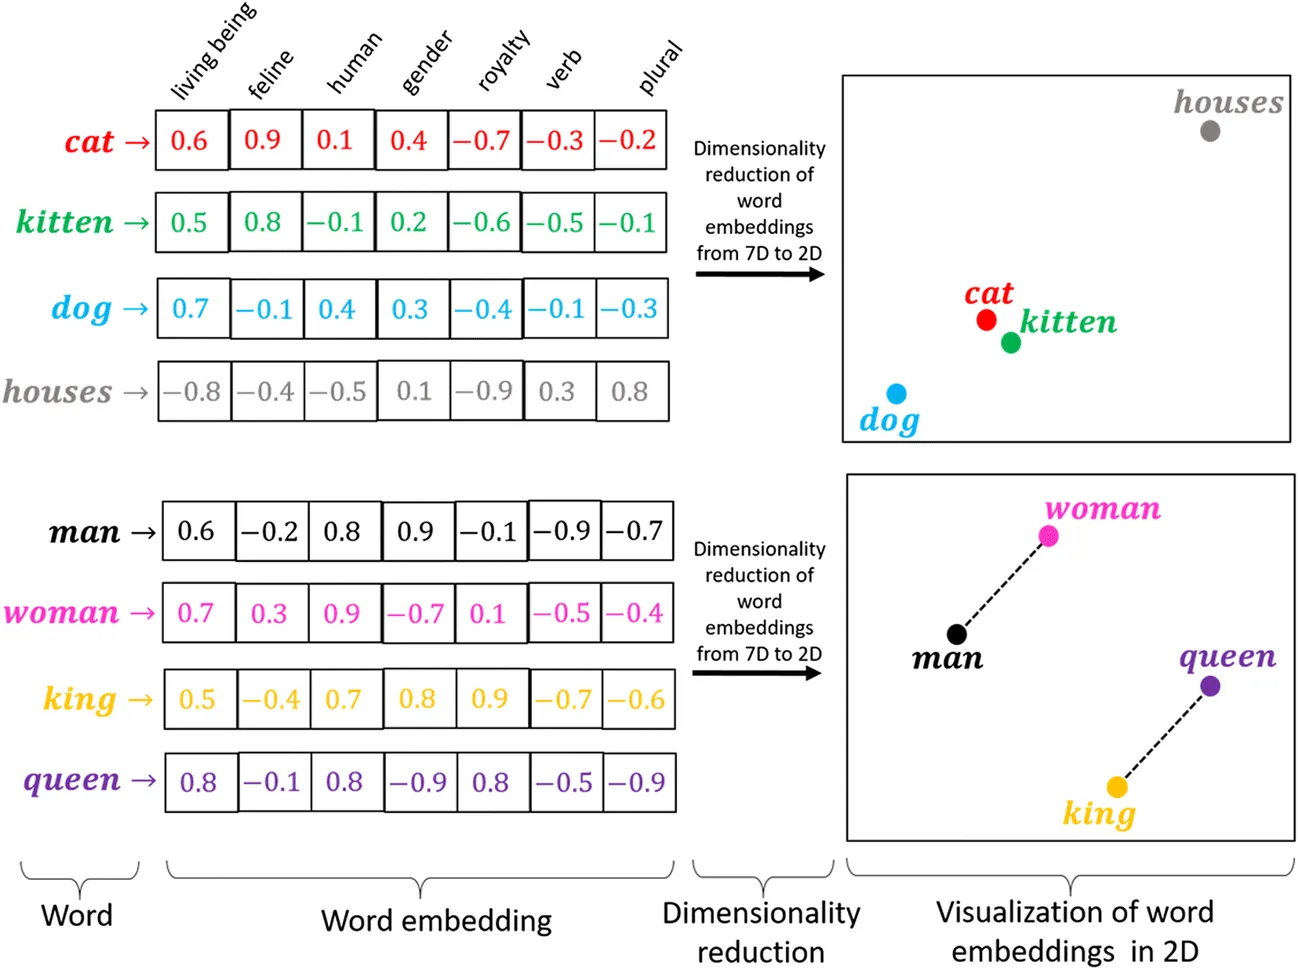


Более популярная и лучшая сеть. Вектора универсальней и точнее для моделей, так как просто слова не дают связи, а вектора дают. Мешок слов статический, а тут и семантический.
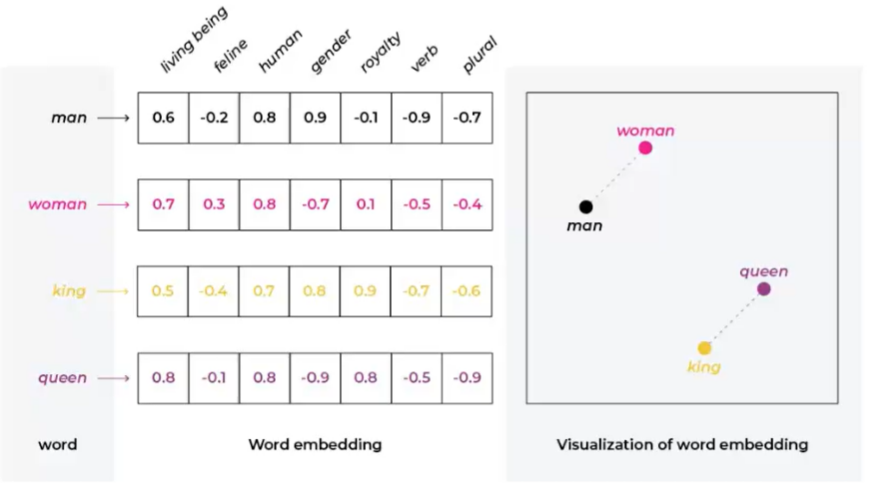
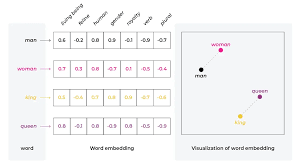

In [7]:
!pip install navec

In [8]:
from navec import Navec


path = 'D:/MIREA/DPO/Learning/Practic2_16/navec_hudlit_v1_12B_500K_300d_100q.tar'
navec = Navec.load(path)
navec

Navec(
    meta=Meta(
        id='hudlit_v1_12B_500K_300d_100q',
        protocol=1
    ),
    vocab=Vocab(words=[...], counts=[...]),
    pq=PQ(
        vectors=np.uint32(500002),
        dim=np.uint32(300),
        qdim=np.uint32(100),
        centroids=np.uint32(256),
        indexes=array([[ 82, 173, 138, ..., 213, 220,  85],
               [189, 124, 167, ...,  62,   4, 188],
               [  3,  21, 222, ...,  74, 152, 109],
               ...,
               [141, 227, 221, ...,  57, 216, 107],
               [ 97, 166,  67, ...,  12, 182,  56],
               [255, 255, 255, ..., 255, 255, 255]],
              shape=(500002, 100), dtype=uint8),
        codes=array([[[ 0.52534044,  0.19559065,  0.09048509],
                [-0.76281834, -0.14530335, -0.26517573],
                [ 0.19408813,  0.21588266,  0.2668593 ],
                ...,
                [-0.27346995,  1.1891862 ,  0.38069752],
                [-0.34461364, -0.16448715,  0.51028794],
                [ 0.      

In [9]:
print(navec['пончик'].shape)
navec['пончик']

(300,)


array([ 0.32549027,  0.1965727 , -0.07332268,  0.02635347, -0.15546265,
       -0.73459977, -0.36643538, -0.15320314,  0.04002705,  0.21500252,
       -0.51616967,  0.2575879 , -0.5842708 ,  0.10114741,  0.16330917,
        0.12804924,  0.85438174, -0.14760202,  0.29688343, -0.11844368,
        0.00928957, -0.33971313,  0.3910974 , -0.38653937, -0.11164437,
        0.21970382,  0.10441626,  0.02137613, -0.02893453,  0.50664586,
        0.14300844, -0.61645526, -0.17848846, -0.19365273, -0.28105956,
        0.02280899,  0.4365262 ,  0.2508373 , -0.35047317,  0.19486012,
       -0.16402894,  0.10202922, -0.11074631,  0.12518995, -0.25656873,
        0.77034795, -0.0941771 ,  0.23481403,  0.31845337,  0.03457986,
       -0.4703636 , -0.01914478,  0.5731501 ,  0.16689321,  0.11686498,
       -0.01905344,  0.4715947 , -0.22624874,  0.15027985, -0.16381185,
       -0.41819286, -0.04846029, -0.11999773, -0.06312657,  0.5727286 ,
       -0.05089949,  0.21825634,  0.66812164, -0.02185797, -0.06

In [10]:
text = 'Мой дядя самых честный правил'
emb_list = []
for word in text.split():
    emb_list.append([word, navec[word.lower()]])
emb_list

[['Мой',
  array([ 0.32431203, -0.4076073 ,  0.03718196, -0.08193679, -0.3621796 ,
         -0.13147986, -0.16435994,  0.11653544, -0.31467173, -0.51748675,
         -0.36825505,  0.16203648, -0.23593628, -0.496698  ,  0.23507702,
          0.20835784, -0.07587578, -0.06125216,  0.42759877, -0.13730636,
         -0.42520824, -0.14115255, -0.36587584,  0.45859212,  0.0837723 ,
          0.36770874, -0.02562836, -0.30762294, -0.17146541,  0.04941745,
         -0.19193137,  0.04902396,  0.8125157 ,  0.16673456, -0.18283887,
          0.3802885 ,  0.02747655, -0.13907251,  0.3825697 , -0.11042376,
         -0.05924853, -0.3166968 ,  0.17956583, -0.04968298, -0.07813525,
         -0.95256674, -0.09760066,  0.41308236, -0.37865356, -0.3504911 ,
         -0.29867902, -0.17751855, -0.262425  ,  0.25024217,  0.2013674 ,
          0.00496217, -0.34787163, -0.14869855,  0.08035463,  0.41909438,
          0.18512656, -0.36358184, -0.15183572, -0.23449601,  0.1664422 ,
          0.02645938, -0.1961

In [11]:
import numpy as np


def get_sentence_vector(sentence):
    words = sentence.split()
    words = [word for word in words if word in navec]
    if not words:
        return None
    vectors = [navec[word] for word in words]
    return np.mean(vectors, axis=0)


text_embedding = get_sentence_vector(text)
text_embedding


array([-0.25508425, -0.28332365, -0.30587652,  0.12786308, -0.2897047 ,
        0.05181138, -0.00400668, -0.1577151 , -0.35022163, -0.0638937 ,
       -0.07605252,  0.04528823, -0.11636281, -0.14504066,  0.02013991,
        0.41205892,  0.04446647,  0.07860711,  0.08837165, -0.10386729,
       -0.11435509, -0.12080185, -0.2532276 ,  0.25090125, -0.33448428,
       -0.01130567,  0.28222358,  0.09422411, -0.01506786,  0.09380849,
       -0.15568957, -0.09139337,  0.60663927,  0.6928653 , -0.00404855,
       -0.07897228, -0.36194125, -0.06804803,  0.0345591 , -0.26910403,
        0.42532182, -0.5099363 , -0.3131542 ,  0.04545112,  0.0437303 ,
       -0.07611673,  0.06306129,  0.01057371, -0.01331302, -0.27248666,
       -0.12887937, -0.22649938, -0.00445845,  0.54732054,  0.25471425,
        0.02741616, -0.06170812, -0.13880527,  0.18614064,  0.12453649,
       -0.27853674, -0.14306849, -0.18355778, -0.10464637,  0.10843953,
        0.17717554, -0.10142961, -0.07632166, -0.08692791, -0.14

In [12]:
def manhattan_distance(word1, word2):
    result = np.sum(abs(word1 - word2))
    return result

def euclidean_distance(word1, word2):
    result = np.linalg.norm(word1 - word2)
    return result

def cosine_distance(word1, word2):
    result = 1 - np.dot(word1, word2) / (np.linalg.norm(word1) * np.linalg.norm(word2))
    return result


print(f'Manhettan:\nэкология + любить:\n{manhattan_distance(navec["экология"], navec["любить"])}')
print(f'Manhettan:\nобожать + любить:\n{manhattan_distance(navec["обожать"], navec["любить"])}')

print(f'Euclidean:\nэкология + любить:\n{euclidean_distance(navec["экология"], navec["любить"])}')
print(f'Euclidean:\nобожать + любить:\n{euclidean_distance(navec["обожать"], navec["любить"])}')

print(f'Cosine:\nэкология + любить:\n{cosine_distance(navec["экология"], navec["любить"])}')
print(f'Cosine:\nобожать + любить:\n{cosine_distance(navec["обожать"], navec["любить"])}')

Manhettan:
экология + любить:
117.36257934570312
Manhettan:
обожать + любить:
70.87225341796875
Euclidean:
экология + любить:
8.623641967773438
Euclidean:
обожать + любить:
5.296801567077637
Cosine:
экология + любить:
1.0199168920516968
Cosine:
обожать + любить:
0.4267292618751526


<h2>Word2Vec</h2>

Точно такие же по устройству. Больше api решений, а значит и шаблонов с весами. Но всё ещё не воспринимает ключи, если их нет. Есть 2 типа: CBOW - предсказание слова по контексту текста и Skip-gram - предсказание контекста по слову

In [13]:
import gensim
import gensim.downloader as download_api


w2v_model = download_api.load('word2vec-ruscorpora-300')


In [14]:
w2v_model.key_to_index

{'весь_DET': 0,
 'человек_NOUN': 1,
 'мочь_VERB': 2,
 'год_NOUN': 3,
 'сказать_VERB': 4,
 'время_NOUN': 5,
 'говорить_VERB': 6,
 'становиться_VERB': 7,
 'знать_VERB': 8,
 'самый_DET': 9,
 'дело_NOUN': 10,
 'день_NOUN': 11,
 'жизнь_NOUN': 12,
 'рука_NOUN': 13,
 'очень_ADV': 14,
 'первый_ADJ': 15,
 'давать_VERB': 16,
 'новый_ADJ': 17,
 'слово_NOUN': 18,
 'иметь_VERB': 19,
 'большой_ADJ': 20,
 'идти_VERB': 21,
 'глаз_NOUN': 22,
 'место_NOUN': 23,
 'лицо_NOUN': 24,
 'видеть_VERB': 25,
 'хотеть_VERB': 26,
 'понимать_VERB': 27,
 'должный_ADJ': 28,
 'работа_NOUN': 29,
 'каждый_DET': 30,
 'друг_NOUN': 31,
 'голова_NOUN': 32,
 'дом_NOUN': 33,
 'оставаться_VERB': 34,
 'сторона_NOUN': 35,
 'начинать_VERB': 36,
 'думать_VERB': 37,
 'хорошо_ADV': 38,
 'жить_VERB': 39,
 'стоять_VERB': 40,
 'спрашивать_VERB': 41,
 'сделать_VERB': 42,
 'выходить_VERB': 43,
 'последний_ADJ': 44,
 'русский_ADJ': 45,
 'сила_NOUN': 46,
 'получать_VERB': 47,
 'какой-то_DET': 48,
 'хороший_ADJ': 49,
 'случай_NOUN': 50,
 'во

Семантическая модель, имеются типы в словах

In [15]:
w2v_model['весна']

KeyError: "Key 'весна' not present"

In [16]:
w2v_model['весна_NOUN']

array([ 0.02016163, -0.01100079,  0.10727151,  0.0682546 ,  0.01818531,
       -0.03252876,  0.04779452, -0.01044511,  0.04060393,  0.00697639,
       -0.0695179 ,  0.07943559,  0.04014143,  0.00230773,  0.00223979,
        0.02042455, -0.06446672,  0.03577725,  0.1017318 , -0.00480211,
       -0.00730318, -0.05861617,  0.03869026,  0.1076944 ,  0.0013582 ,
       -0.05651233, -0.0450992 , -0.05783464, -0.00204637,  0.03687766,
        0.06182311,  0.02977616, -0.06497473,  0.0318776 ,  0.01033847,
        0.03192691, -0.0612511 ,  0.00559575, -0.07240581, -0.01028931,
        0.02257385,  0.04308167,  0.01872673,  0.04375739, -0.09489343,
       -0.06254882,  0.12214403, -0.12721089, -0.0713633 ,  0.0242544 ,
        0.00075993,  0.02791287, -0.01821486,  0.01105471, -0.12433429,
       -0.04057381,  0.07100547, -0.02605199, -0.11987958,  0.07657392,
        0.05288683, -0.05368467, -0.06283479, -0.00301035, -0.02266693,
        0.03049994, -0.00884082,  0.0201887 , -0.01785147, -0.04

In [17]:
print(f'Manhettan:\nэкология + любить:\n{manhattan_distance(w2v_model["экология_NOUN"], w2v_model["любить_VERB"])}')
print(f'Manhettan:\nобожать + любить:\n{manhattan_distance(w2v_model["обожать_VERB"], w2v_model["любить_VERB"])}')

print(f'Euclidean:\nэкология + любить:\n{euclidean_distance(w2v_model["экология_NOUN"], w2v_model["любить_VERB"])}')
print(f'Euclidean:\nобожать + любить:\n{euclidean_distance(w2v_model["обожать_VERB"], w2v_model["любить_VERB"])}')

print(f'Cosine:\nэкология + любить:\n{cosine_distance(w2v_model["экология_NOUN"], w2v_model["любить_VERB"])}')
print(f'Cosine:\nобожать + любить:\n{cosine_distance(w2v_model["обожать_VERB"], w2v_model["любить_VERB"])}')

Manhettan:
экология + любить:
18.096017837524414
Manhettan:
обожать + любить:
9.346719741821289
Euclidean:
экология + любить:
1.3482294082641602
Euclidean:
обожать + любить:
0.684089183807373
Cosine:
экология + любить:
0.9088612794876099
Cosine:
обожать + любить:
0.23398900032043457


In [18]:
print(w2v_model.cosine_similarities(w2v_model['экология_NOUN'], [w2v_model['любить_VERB']]))

print(w2v_model.cosine_similarities(w2v_model['обожать_VERB'], [w2v_model['любить_VERB']]))

[0.09113873]
[0.766011]


In [19]:
print(w2v_model.distances('экология_NOUN', ['любить_VERB', 'ненавидеть_VERB']))
print(w2v_model.distances('обожать_VERB', ['любить_VERB', 'ненавидеть_VERB']))

[0.9088613 0.924238 ]
[0.23398888 0.4001112 ]


In [20]:
def get_sentence_vector(sentence):
    words = sentence.split()
    words = [word for word in words if word in w2v_model.key_to_index]
    if not words:
        return None
    vectors = [w2v_model[word] for word in words]
    return np.mean(vectors, axis=0)


text = 'победа_NOUN была_VERB очень_ADV ценна_ADJ'
print(get_sentence_vector(text))

[-1.07823946e-02 -1.56256557e-03  5.35215847e-02 -1.58525612e-02
 -5.03347255e-02 -7.30733387e-04  2.14498714e-02 -5.02481684e-03
 -1.90432556e-03 -1.45689892e-02  4.38738205e-02 -6.17116950e-02
  1.85797289e-02 -4.35574278e-02  5.10439910e-02 -1.96378920e-02
  1.36739379e-02 -4.10806164e-02  2.20123008e-02  3.09401639e-02
 -5.18377572e-02  1.39373140e-02 -9.61817615e-03 -6.71993941e-04
  2.72361469e-02 -7.23175630e-02  2.40086950e-02 -5.98272607e-02
  1.26039553e-02 -2.02301927e-02  5.71368784e-02 -4.32991236e-02
  2.96254270e-03 -3.42750475e-02  8.50814953e-03  1.74648277e-02
  5.59802391e-02 -5.73884472e-02 -2.48593055e-02  1.40643772e-02
  4.50558513e-02  5.83555773e-02  1.60142779e-04  5.33329174e-02
  5.07769734e-03  3.46052498e-02 -1.20273484e-02 -6.18573204e-02
  3.61332297e-02 -4.93400022e-02 -2.89910957e-02  7.10709840e-02
  7.47602656e-02 -3.90710607e-02  5.54988720e-02 -4.81834374e-02
  4.03473945e-03  1.80117916e-02  3.13686207e-02  3.17508243e-02
 -4.71853465e-02 -2.00494

<h2>FastText

In [26]:
import fasttext


ft_model = fasttext.load_model('D:/MIREA/DPO/Learning/Models/cc.ru.300.bin/cc.ru.300.bin')
ft_model['воововрвр']

array([ 9.30131972e-03,  2.54129302e-02,  3.76102515e-02,  2.83273272e-02,
       -7.09985834e-05, -1.47110652e-02, -8.52149539e-03,  2.90066539e-03,
       -6.47164462e-03,  1.45498477e-02,  5.44599490e-03, -1.63453892e-02,
       -1.37950741e-02,  6.73977053e-03, -9.76888370e-03,  1.94315296e-02,
        9.89816338e-03,  6.02498604e-03,  5.63058956e-03,  2.10052263e-02,
       -2.74178851e-03, -5.25927097e-02,  1.39902318e-02,  4.26782221e-02,
       -1.71848349e-02, -9.02861648e-04, -3.48145375e-03,  1.87300276e-02,
        3.92023027e-02,  1.81726217e-02,  2.07594186e-02, -2.30996870e-02,
       -9.81356669e-03,  8.86008516e-03,  2.88681430e-03,  1.56639796e-02,
       -1.11381931e-04, -2.91641150e-02, -1.95278171e-02,  6.62898785e-03,
        3.21649574e-02, -2.71602310e-02,  9.73117631e-03,  8.44171550e-03,
       -3.14248800e-02,  5.37539925e-03,  1.33571466e-02,  1.26111237e-02,
        6.36956245e-02, -5.48349414e-03, -1.38129964e-02,  2.18710937e-02,
       -1.73790657e-04,  

In [28]:
ft_model.get_nearest_neighbors('любить')

[(0.8195568323135376, 'Любить'),
 (0.8013368248939514, 'ненавидеть'),
 (0.7641687989234924, 'обожать'),
 (0.7576323747634888, 'нелюбить'),
 (0.7561174035072327, 'любить.'),
 (0.7212936878204346, 'полюбить'),
 (0.7191895842552185, 'боготворить'),
 (0.7092794179916382, 'влюбляться'),
 (0.6996907591819763, 'ЛЮБИТЬ'),
 (0.6909425258636475, 'любиться')]

In [30]:
print(f'Manhettan:\nэкология + любить:\n{manhattan_distance(ft_model["экология"], ft_model["любить"])}')
print(f'Manhettan:\nобожать + любить:\n{manhattan_distance(ft_model["обожать"], ft_model["любить"])}')

print(f'Euclidean:\nэкология + любить:\n{euclidean_distance(ft_model["экология"], ft_model["любить"])}')
print(f'Euclidean:\nобожать + любить:\n{euclidean_distance(ft_model["обожать"], ft_model["любить"])}')

print(f'Cosine:\nэкология + любить:\n{cosine_distance(ft_model["экология"], ft_model["любить"])}')
print(f'Cosine:\nобожать + любить:\n{cosine_distance(ft_model["обожать"], ft_model["любить"])}')

Manhettan:
экология + любить:
16.181068420410156
Manhettan:
обожать + любить:
8.692635536193848
Euclidean:
экология + любить:
1.1492985486984253
Euclidean:
обожать + любить:
0.6161932349205017
Cosine:
экология + любить:
0.9307494759559631
Cosine:
обожать + любить:
0.23583096265792847


In [33]:
text = 'Хочу, чтобы люди закончились, я устал'
ft_model.get_sentence_vector(text)

array([ 2.80296057e-02, -4.58938889e-02,  9.43530165e-03,  3.53540815e-02,
        6.84260298e-03, -4.56967438e-03, -6.33212132e-03,  2.15488877e-02,
       -3.59126218e-02, -2.16678232e-02,  2.12414749e-02, -6.15420341e-02,
        3.14857215e-02,  9.26837325e-03, -3.36027667e-02, -3.91999260e-03,
        4.23482340e-03, -2.39679031e-02, -2.98739225e-02, -3.74040194e-03,
       -9.64081567e-03, -3.23742852e-02, -4.57876474e-02,  5.41219078e-02,
       -1.39710484e-02,  4.82851528e-02, -1.89412460e-02, -2.91688554e-02,
        1.55414976e-02, -4.79120873e-02, -1.43536730e-02, -6.04502670e-03,
       -5.88115305e-03, -5.62135316e-03,  6.12299554e-02, -1.00392820e-02,
        2.05546170e-02, -1.59906149e-01,  4.99843433e-02, -9.52505600e-03,
       -1.95220690e-02, -9.07074064e-02, -8.23218748e-03,  2.75399201e-02,
       -3.25739421e-02,  1.11994275e-03, -4.41464186e-02, -6.34648791e-03,
        3.45613360e-02,  5.42183314e-03,  2.05452498e-02,  3.33904326e-02,
        1.95267552e-03,  

<h1><center>Практическое задание</center></h1>

1. Найти текстовый корпус для классификации текстов
2. Почистить его, используя изветсные вам методы
3. Преобразовать текста в векторные представления и сравнить их на схожесть между собой
4. Преобразовать исходный корпус в мешок слов и обучить с его помощью линейную модель классификации